In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import seaborn as sns

In [2]:
x, y = make_moons(n_samples=1000, noise=0.2)

In [3]:
df = {"x1": x[:, 0],"x2": x[:, 1],"y": y}
dataset = pd.DataFrame(df)
dataset

,x1,x2,y
0,1.216857,-0.417373,1
1,1.596207,-0.471736,1
2,0.171780,-0.273172,1
3,1.908155,-0.321922,1
4,0.919359,-0.101997,0
...,...,...,...
995,-0.686538,1.041224,0
996,-0.054529,0.083143,1
997,0.498938,0.126657,0
998,1.286256,0.357349,0


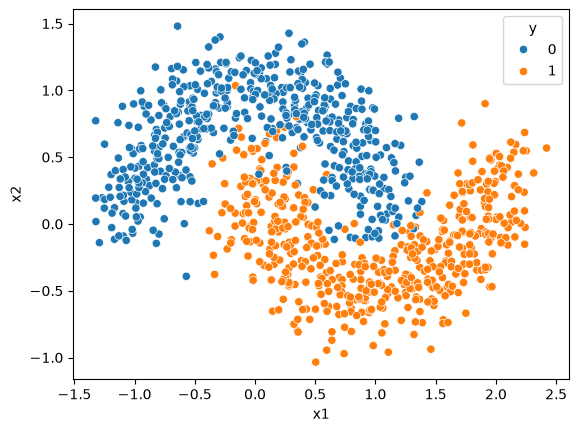

In [4]:
sns.scatterplot(x="x1", y="x2", data=dataset, hue="y")
plt.show()

In [5]:
x_a = dataset.iloc[:, :-1]
y_a = dataset["y"]

In [6]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_a,y_a,test_size=0.2,random_state=42)

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

In [8]:
dt = DecisionTreeClassifier()
dt.fit(x_train, y_train)
dt.score(x_train, y_train) * 100, dt.score(x_test, y_test) * 100

(100.0, 96.0)

In [9]:
sv = SVC()
sv.fit(x_train, y_train)
sv.score(x_train, y_train) * 100, sv.score(x_test, y_test) * 100

(95.875, 96.5)

In [10]:
gnb = GaussianNB()
gnb.fit(x_train, y_train)
gnb.score(x_train, y_train) * 100, gnb.score(x_test, y_test) * 100

(87.75, 82.5)

# Use the Voting Classifier for Max Voting

In [11]:
from sklearn.ensemble import VotingClassifier

In [12]:
li = [("dt1", DecisionTreeClassifier()),("sv1", SVC()),("gnb1", GaussianNB())]

In [13]:
vc = VotingClassifier(li)
vc.fit(x_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('dt1', ...), ('sv1', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[DecisionTreeClassifier(), SVC(), GaussianNB()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['x1','x2']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [14]:
vc.score(x_train, y_train) * 100, vc.score(x_test, y_test) * 100

(97.0, 95.5)

In [15]:
prd = {"dt": dt.predict(x_test),"svm": sv.predict(x_test),"gnb": gnb.predict(x_test),"vc": vc.predict(x_test)}
pd.DataFrame(prd)

,dt,svm,gnb,vc
0,1,1,1,1
1,0,0,0,0
2,1,1,1,1
3,1,1,0,1
4,1,1,1,1
...,...,...,...,...
195,1,1,1,1
196,1,1,1,1
197,1,1,1,1
198,0,0,1,0
